# CÀI ĐẶT THUẬT TOÁN

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

def standardize(X, mean=None, std=None):
    if mean is None:
        mean = np.mean(X, axis=0)
    if std is None:
        std = np.std(X, axis=0)
        std[std == 0] = 1.0
    return (X - mean) / std, mean, std

def hinge_loss(X, y, w, b, C):
    margins = 1 - y * (X @ w + b)
    losses = np.maximum(0, margins)
    return 0.5 * (w @ w) + C * np.mean(losses)

def train_svm_sgd(X, y, C=1.0, lr=0.001, epochs=50, batch_size=64):
    np.random.seed(42)
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    b = 0.0
    loss_history = []

    for epoch in range(epochs):
        indices = np.random.permutation(n_samples)
        X_shuffled = X[indices]
        y_shuffled = y[indices]

        for i in range(0, n_samples, batch_size):
            X_batch = X_shuffled[i:i+batch_size]
            y_batch = y_shuffled[i:i+batch_size]

            margins = y_batch * (X_batch @ w + b)
            mask = margins < 1

            dw = w - C * np.mean((y_batch[mask, None] * X_batch[mask]), axis=0) if np.any(mask) else w
            db = -C * np.mean(y_batch[mask]) if np.any(mask) else 0.0

            w = w - lr * dw
            b = b - lr * db

        loss = hinge_loss(X, y, w, b, C)
        loss_history.append(loss)

    return w, b, loss_history

def predict_svm(X, w, b):
    return np.where(X @ w + b >= 0, 1, -1)

def compute_metrics(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == -1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == -1))

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return precision, recall, f1

# TIỀN XỬ LÝ DỮ LIỆU

In [3]:
df = pd.read_csv('../../Lab01/2/sp500_yahoo.csv')
df = df[df['Volume'] > 0].dropna().reset_index(drop=True)

df['Range'] = (df['High'] - df['Low']) / df['Open']
df['Mid_Diff'] = ((df['High'] + df['Low']) / 2 - df['Open']) / df['Open']
df['Log_Vol'] = np.log1p(df['Volume'])

features = ['Open', 'High', 'Low', 'Range', 'Mid_Diff', 'Log_Vol']
X = df[features].values
y = np.where(df['Close'].values > df['Open'].values, 1, -1)

split_idx = int(0.8 * len(X))
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

X_train_scaled, mean_train, std_train = standardize(X_train)
X_test_scaled, _, _ = standardize(X_test, mean_train, std_train)

print(f'Train shape: {X_train_scaled.shape}, Test shape: {X_test_scaled.shape}')
print(f'Ty le nhan +1 trong tap train: {np.mean(y_train == 1):.4f}')

Train shape: (15444, 6), Test shape: (3862, 6)
Ty le nhan +1 trong tap train: 0.4215


# HUẤN LUYỆN MÔ HÌNH

In [4]:
start_time = time.time()
w, b, loss_history = train_svm_sgd(X_train_scaled, y_train, C=10.0, lr=0.005, epochs=60, batch_size=128)
train_time = time.time() - start_time

y_pred = predict_svm(X_test_scaled, w, b)
precision, recall, f1 = compute_metrics(y_test, y_pred)

print(f'Thoi gian huan luyen: {train_time:.4f}s')
print(f'Precision: {precision:.4f}')
print(f'Recall:    {recall:.4f}')
print(f'F1-Score:  {f1:.4f}')

Thoi gian huan luyen: 0.2342s
Precision: 0.8749
Recall:    0.8160
F1-Score:  0.8444


# VẼ ĐỒ THỊ

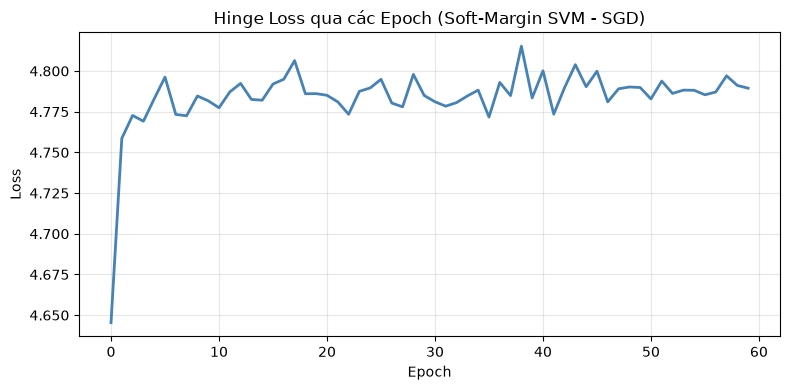

In [5]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history, color='steelblue', linewidth=2)
plt.title('Hinge Loss qua các Epoch (Soft-Margin SVM - SGD)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()